# 🔭 Assignment: Measuring Cosmological Parameters Using Type Ia Supernovae

In this assignment, you'll analyze observational data from the Pantheon+SH0ES dataset of Type Ia supernovae to measure the Hubble constant $H_0$ and estimate the age of the universe. You will:

- Plot the Hubble diagram (distance modulus vs. redshift)
- Fit a cosmological model to derive $H_0$ and $\Omega_m$
- Estimate the age of the universe
- Analyze residuals to assess the model
- Explore the effect of fixing $\Omega_m$
- Compare low-z and high-z results

Let's get started!


## 📦 Getting Started: Setup and Libraries

Before we dive into the analysis, we need to import the necessary Python libraries:

- `numpy`, `pandas` — for numerical operations and data handling
- `matplotlib` — for plotting graphs
- `scipy.optimize.curve_fit` and `scipy.integrate.quad` — for fitting cosmological models and integrating equations
- `astropy.constants` and `astropy.units` — for physical constants and unit conversions

Make sure these libraries are installed in your environment. If not, you can install them using:

```bash
pip install numpy pandas matplotlib scipy astropy


In [1]:
!pip install scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import quad
from astropy.constants import c
from astropy import units as u

## 📂 Load the Pantheon+SH0ES Dataset

We now load the observational supernova data from the Pantheon+SH0ES sample. This dataset includes calibrated distance moduli $\mu$, redshifts corrected for various effects, and uncertainties.

### Instructions:
- Make sure the data file is downloaded from [Pantheon dataset](https://github.com/PantheonPlusSH0ES/DataRelease/blob/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/Pantheon%2BSH0ES.dat) and available locally.
- We use `delim_whitespace=True` because the file is space-delimited rather than comma-separated.
- Commented rows (starting with `#`) are automatically skipped.

We will extract:
- `zHD`: Hubble diagram redshift
- `MU_SH0ES`: Distance modulus using SH0ES calibration
- `MU_SH0ES_ERR_DIAG`: Associated uncertainty


More detailed column names and the meanings can be referred here:

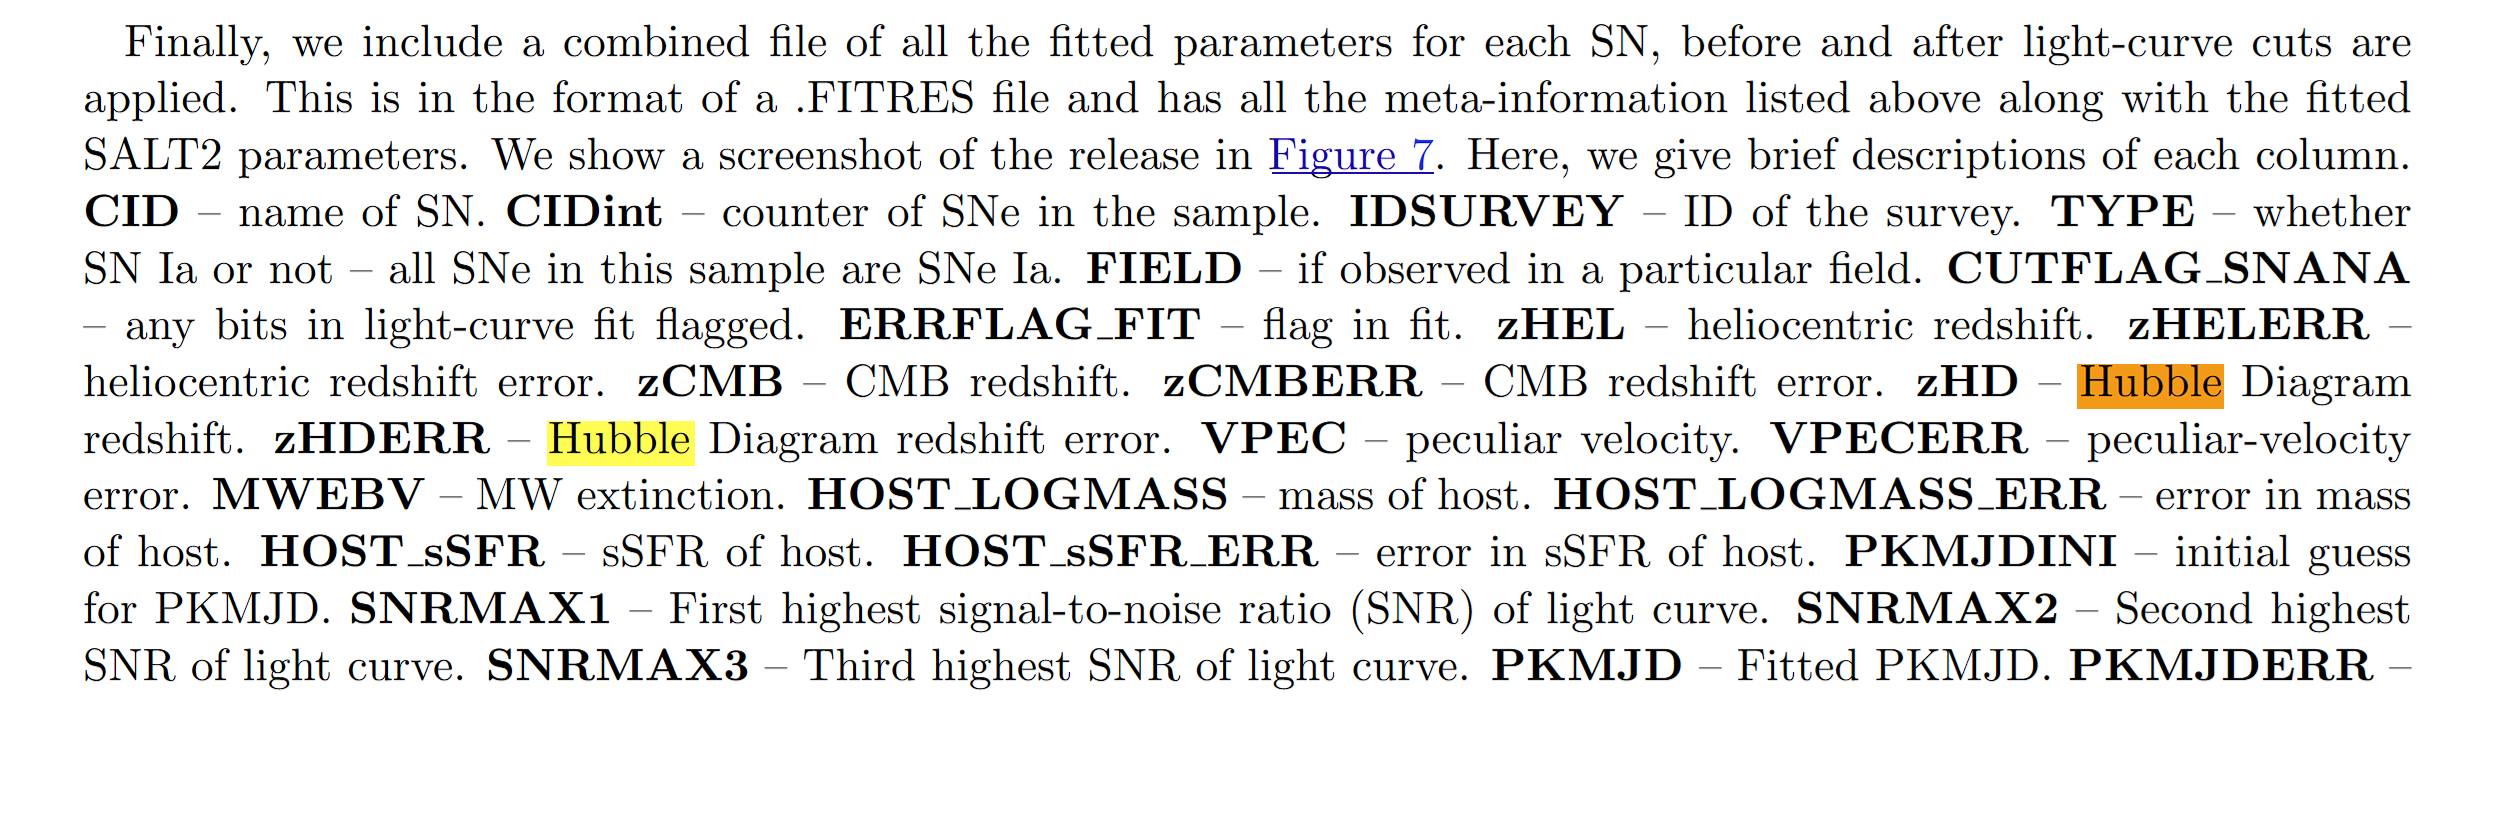

In [3]:
# Local file path
file_path = "Pantheon+SH0ES.dat"

# Load the file
#file = pd.read_csv(file_path, delim_whitespace = True)
file = pd.read_csv(file_path, sep = r'\s+')
# See structure

file.describe()

,IDSURVEY,zHD,zHDERR,zCMB,zCMBERR,zHEL,zHELERR,m_b_corr,m_b_corr_err_DIAG,MU_SH0ES,...,PKMJDERR,NDOF,FITCHI2,FITPROB,m_b_corr_err_RAW,m_b_corr_err_VPEC,biasCor_m_b,biasCorErr_m_b,biasCor_m_b_COVSCALE,biasCor_m_b_COVADD
count,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.00000,1701.000000,1701.000000,1701.000000,1701.000000,...,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000
mean,37.017637,0.221229,0.001840,0.221090,0.001155,0.22143,0.001155,19.083629,0.240920,38.336629,...,0.384440,36.499118,47.227484,0.469040,0.104899,0.061886,-0.009629,0.004541,0.972350,0.008889
std,45.916840,0.249271,0.002593,0.249337,0.002774,0.24944,0.002774,3.374499,0.098815,3.374499,...,0.473585,23.891781,67.434767,0.378961,0.055224,0.096221,0.074649,0.005048,0.089824,0.009789
min,1.000000,0.001220,0.000840,0.001220,0.000000,0.00082,0.000000,9.745710,0.111583,28.998700,...,0.004500,0.000000,0.219440,0.000000,0.034300,0.004300,-0.535600,0.000000,0.164000,0.000000
25%,4.000000,0.027730,0.000860,0.027210,0.000020,0.02716,0.000020,16.036200,0.178788,35.289200,...,0.138200,20.000000,18.316200,0.062870,0.065700,0.010800,-0.050900,0.002000,1.000000,0.003000
50%,15.000000,0.163750,0.001030,0.163570,0.000150,0.16470,0.000150,20.076300,0.217323,39.329300,...,0.269100,34.000000,33.036300,0.441920,0.087100,0.028800,0.001500,0.003000,1.000000,0.006000
75%,57.000000,0.328680,0.001480,0.328590,0.001000,0.32961,0.001000,21.824800,0.278656,41.077800,...,0.483700,48.000000,51.953600,0.865830,0.124800,0.076900,0.034500,0.005000,1.000000,0.012000
max,150.000000,2.261370,0.040060,2.261300,0.040000,2.26000,0.040000,26.929800,1.517230,46.182800,...,6.310000,280.000000,1106.220000,1.000000,0.493300,1.496000,0.365300,0.050000,1.000000,0.063000


In [4]:
file.head()

,CID,IDSURVEY,zHD,zHDERR,zCMB,zCMBERR,zHEL,zHELERR,m_b_corr,m_b_corr_err_DIAG,...,PKMJDERR,NDOF,FITCHI2,FITPROB,m_b_corr_err_RAW,m_b_corr_err_VPEC,biasCor_m_b,biasCorErr_m_b,biasCor_m_b_COVSCALE,biasCor_m_b_COVADD
0,2011fe,51,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.74571,1.516210,...,0.1071,36,26.8859,0.864470,0.0991,1.4960,0.0381,0.005,1.0,0.003
1,2011fe,56,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.80286,1.517230,...,0.0579,101,88.3064,0.812220,0.0971,1.4960,-0.0252,0.003,1.0,0.004
2,2012cg,51,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.47030,0.781906,...,0.0278,165,233.5000,0.000358,0.0399,0.7134,0.0545,0.019,1.0,0.036
3,2012cg,56,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.49190,0.798612,...,0.0667,55,100.1220,0.000193,0.0931,0.7134,0.0622,0.028,1.0,0.040
4,1994DRichmond,50,0.00299,0.00084,0.00299,0.00004,0.00187,0.00004,11.52270,0.880798,...,0.0522,146,109.8390,0.988740,0.0567,0.6110,0.0650,0.009,1.0,0.006


## 🧾 Preview Dataset Columns

Before diving into the analysis, let’s take a quick look at the column names in the dataset. This helps us verify the data loaded correctly and identify the relevant columns we’ll use for cosmological modeling.


In [5]:
file.columns

Index(['CID', 'IDSURVEY', 'zHD', 'zHDERR', 'zCMB', 'zCMBERR', 'zHEL',
       'zHELERR', 'm_b_corr', 'm_b_corr_err_DIAG', 'MU_SH0ES',
       'MU_SH0ES_ERR_DIAG', 'CEPH_DIST', 'IS_CALIBRATOR', 'USED_IN_SH0ES_HF',
       'c', 'cERR', 'x1', 'x1ERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c',
       'COV_x1_x0', 'COV_c_x0', 'RA', 'DEC', 'HOST_RA', 'HOST_DEC',
       'HOST_ANGSEP', 'VPEC', 'VPECERR', 'MWEBV', 'HOST_LOGMASS',
       'HOST_LOGMASS_ERR', 'PKMJD', 'PKMJDERR', 'NDOF', 'FITCHI2', 'FITPROB',
       'm_b_corr_err_RAW', 'm_b_corr_err_VPEC', 'biasCor_m_b',
       'biasCorErr_m_b', 'biasCor_m_b_COVSCALE', 'biasCor_m_b_COVADD'],
      dtype='object')

## 🧹 Clean and Extract Relevant Data

To ensure reliable fitting, we remove any rows that have missing values in key columns:

- `zHD`: redshift for the Hubble diagram  
- `MU_SH0ES`: distance modulus  
- `MU_SH0ES_ERR_DIAG`: uncertainty in the distance modulus  

We then extract these cleaned columns as NumPy arrays to prepare for analysis and modeling.


In [4]:
# Filter for entries with usable data based on the required columns
key_cols = ['zHD', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG']
file_clean = file.dropna(subset = key_cols)
z = file_clean['zHD'].to_numpy()
mu = file_clean['MU_SH0ES'].to_numpy()
mu_err = file_clean['MU_SH0ES_ERR_DIAG'].to_numpy()

## 📈 Plot the Hubble Diagram

Let’s visualize the relationship between redshift $z$ and distance modulus $\mu$, known as the Hubble diagram. This plot is a cornerstone of observational cosmology—it allows us to compare supernova observations with theoretical predictions based on different cosmological models.

We use a logarithmic scale on the redshift axis to clearly display both nearby and distant supernovae.


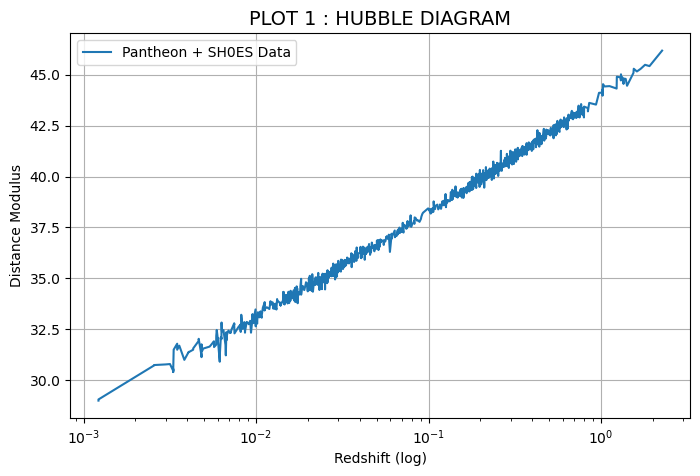

In [21]:
# Write a code to plot the distance modulus and the redshift (x-axis), label them accordingly. 
plt.figure(figsize = (8,5))
plt.title('PLOT 1 : HUBBLE DIAGRAM', fontsize = 14)
plt.xlabel('Redshift (log)', fontsize = 10)
plt.ylabel('Distance Modulus')
#Try using log scale in x-axis
plt.xscale('log')
plt.plot(z, mu, label='Pantheon + SH0ES Data', linestyle='-')

plt.grid()
plt.legend()
plt.show()


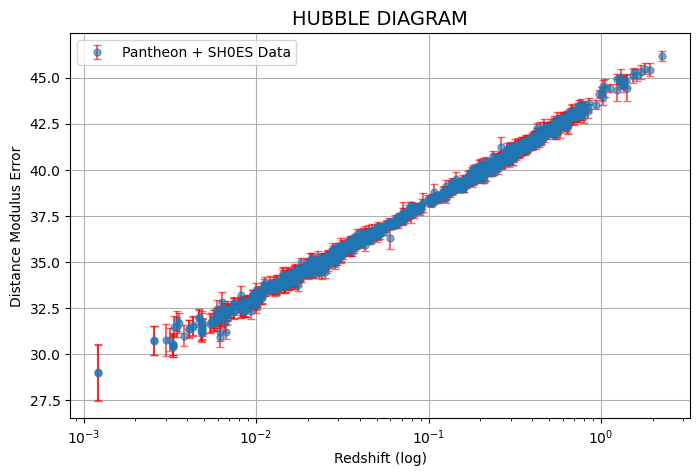

In [22]:
plt.figure(figsize = (8,5))
plt.title('HUBBLE DIAGRAM', fontsize = 14)
plt.xlabel('Redshift (log)', fontsize = 10)
plt.ylabel('Distance Modulus Error')
plt.xscale('log')
plt.errorbar(z, mu, yerr=mu_err, fmt='o', alpha = 0.6, markersize = 5, label='Pantheon + SH0ES Data', ecolor='red', capsize=3)

plt.grid()
plt.legend()
plt.show()


## 🧮 Define the Cosmological Model

We now define the theoretical framework based on the flat $\Lambda\mathrm{CDM}$ model (read about the model in wikipedia if needed). This involves:

- The dimensionless Hubble parameter:
  $$
  E(z) = \sqrt{\Omega_m (1+z)^3 + (1 - \Omega_m)}
  $$

- The distance modulus is:
  $$
  \mu(z) = 5 \log_{10}(d_L / \text{Mpc}) + 25
  $$

- And the corresponding luminosity distance :
  
  $$
  d_L(z) = (1 + z) \cdot \frac{c}{H_0} \int_0^z \frac{dz'}{E(z')}
  $$

These equations allow us to compute the expected distance modulus from a given redshift $z$, Hubble constant $H_0$, and matter density parameter $\Omega_m$.


In [23]:
# Define the E(z) for flat LCDM
def E(z, Omega_m):
    return np.sqrt(Omega_m * ((1 + z) ** 3)  + (1 - Omega_m))


# Luminosity distance in Mpc, try using scipy quad to integrate.
def luminosity_distance(z, H0, Omega_m):
    integrand = lambda z_prime: 1.0 / E(z_prime, Omega_m)
    integral, _ = quad(integrand, 0, z)
    d_H = (c.to(u.km / u.s).value) / H0
    d_L = (1 + z) * d_H * integral
    return d_L

# Theoretical distance modulus, use above function inside mu_theory to compute luminosity distance 
def mu_theory(z, H0, Omega_m):
    if np.isscalar(z):                                       # For scalar input (quad)
        d_L = luminosity_distance(z, H0, Omega_m)
        return (5 * np.log10(d_L) + 25)
    else:                                                    # For array input (curve_fit)
        return np.array([5 * np.log10(luminosity_distance(zi, H0, Omega_m)) + 25 for zi in z])


## 🔧 Fit the Model to Supernova Data

We now perform a non-linear least squares fit to the supernova data using our theoretical model for $\mu(z)$. This fitting procedure will estimate the best-fit values for the Hubble constant $ H_0$ and matter density parameter $\Omega_m$, along with their associated uncertainties.

We'll use:
- `curve_fit` from `scipy.optimize` for the fitting.
- The observed distance modulus \(\mu\), redshift \(z\), and measurement errors.

The initial guess is:
- $ H_0 = 70 \, \text{km/s/Mpc} $
- $\Omega_m =0.3$


In [30]:
#H_guess = 70.0
#omega_guess = 0.3
#z_vals = np.array([0.01, 0.1, 0.5, 1.0])
#mu_vals = mu_theory(z_vals, H_guess, omega_guess)
#print(mu_vals)


In [24]:
# Initial guess: H0 = 70, Omega_m = 0.3
H_guess = 70.0
omega_guess = 0.3
p0 = [H_guess, omega_guess]

# Write a code for fitting and taking error out of the parameters
popt, pcov = curve_fit(mu_theory, z, mu, sigma=mu_err, p0=p0, absolute_sigma=True)
H0_fit, Omega_m_fit = popt
H0_err, Omega_m_err = np.sqrt(np.diag(pcov))

print(f"Fitted H0 = {H0_fit:.2f} ± {H0_err:.2f} km/s/Mpc")
print(f"Fitted Omega_m = {Omega_m_fit:.3f} ± {Omega_m_err:.3f}")


Fitted H0 = 72.97 ± 0.26 km/s/Mpc
Fitted Omega_m = 0.351 ± 0.019


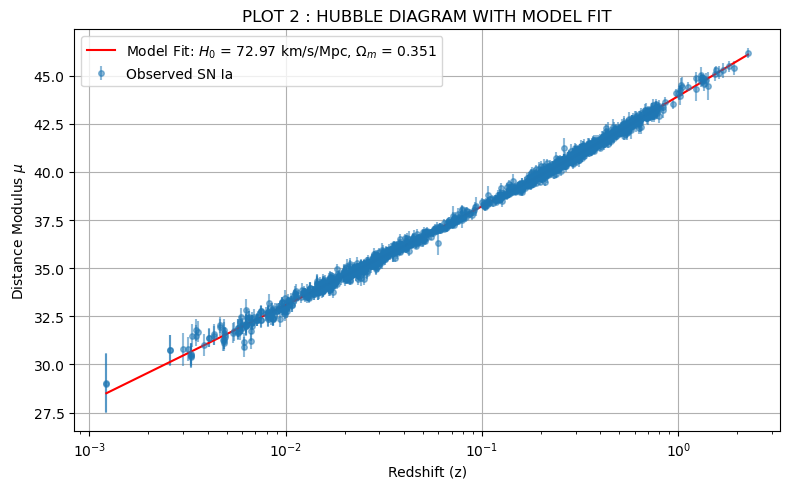

In [29]:
# Best-fit values from curve_fit
H0 = H0_fit
Omega_m = Omega_m_fit

# Compute model μ values at data z
mu_fit = mu_theory(z, H0, Omega_m)

# Plot Hubble Diagram
plt.figure(figsize=(8, 5))
plt.errorbar(z, mu, yerr=mu_err, fmt='o', markersize=4, alpha=0.5, label='Observed SN Ia')
plt.plot(z, mu_fit, color='red', label=rf'Model Fit: $H_0$ = {H0:.2f} km/s/Mpc, $\Omega_m$ = {Omega_m:.3f}')
plt.xscale('log')
plt.xlabel('Redshift (z)')
plt.ylabel(r'Distance Modulus $\mu$')
plt.title('PLOT 2 : HUBBLE DIAGRAM WITH MODEL FIT')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## ⏳ Estimate the Age of the Universe

Now that we have the best-fit values of $ H_0 $ and $ \Omega_m $, we can estimate the age of the universe. This is done by integrating the inverse of the Hubble parameter over redshift:

$$
t_0 = \int_0^\infty \frac{1}{(1 + z) H(z)} \, dz
$$

We convert $ H_0 $ to SI units and express the result in gigayears (Gyr). This provides an independent check on our cosmological model by comparing the estimated age to values from other probes like Planck CMB measurements.


In [25]:
# Write the function for age of the universe as above

def age_of_universe(H0, Omega_m):
    integrand = lambda z: 1.0 / ((1 + z) * E(z, Omega_m))
    integral, _ = quad(integrand, 0, np.inf)
    
    H0 = H0 * u.km / u.s / u.Mpc  # Convert to proper units
    t_H = (1 / H0).to(u.Gyr)      # Hubble time in Gyr

    t_0 = t_H * integral          # Age of universe = t_H * integral
    return t_0.value   # in Gyr

t0 = age_of_universe(H0_fit, Omega_m_fit)
print(f"Estimated age of Universe: {t0:.2f} Gyr")
#t0_planck = age_of_universe(67.66, 0.3111)
#print(f"Planck ΛCDM Age of Universe: {t0_planck:.2f} Gyr")


Estimated age of Universe: 12.36 Gyr


## 📊 Analyze Residuals

To evaluate how well our cosmological model fits the data, we compute the residuals:

$$
\text{Residual} = \mu_{\text{obs}} - \mu_{\text{model}}
$$

Plotting these residuals against redshift helps identify any systematic trends, biases, or outliers. A good model fit should show residuals scattered randomly around zero without any significant structure.


In [12]:
mu_model = mu_theory(z, *popt)
chi2 = np.sum(((mu - mu_model) / mu_err) ** 2)
dof = len(mu) - len(popt)
chi2_red = chi2 / dof


print(f"dof = {dof:.2f}, Chi² = {chi2:.2f}, Reduced Chi² = {chi2_red:.2f}")

dof = 1699.00, Chi² = 745.40, Reduced Chi² = 0.44


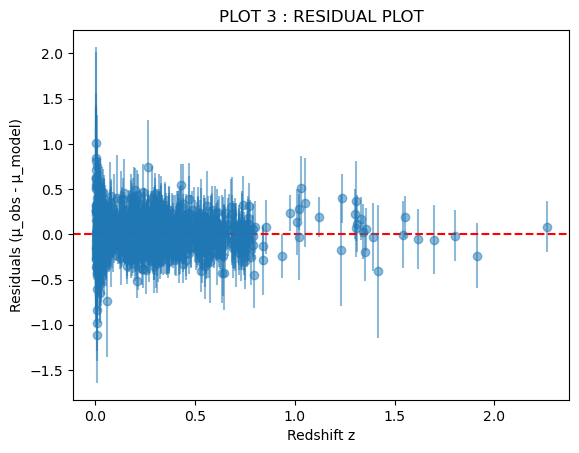

In [30]:
# Write the code to find residual by computing mu_theory and then plot

residuals = mu - mu_model
plt.errorbar(z, residuals, yerr=mu_err, fmt='o', alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Redshift z")
plt.ylabel("Residuals (μ_obs - μ_model)")
plt.title("PLOT 3 : RESIDUAL PLOT")
plt.show()


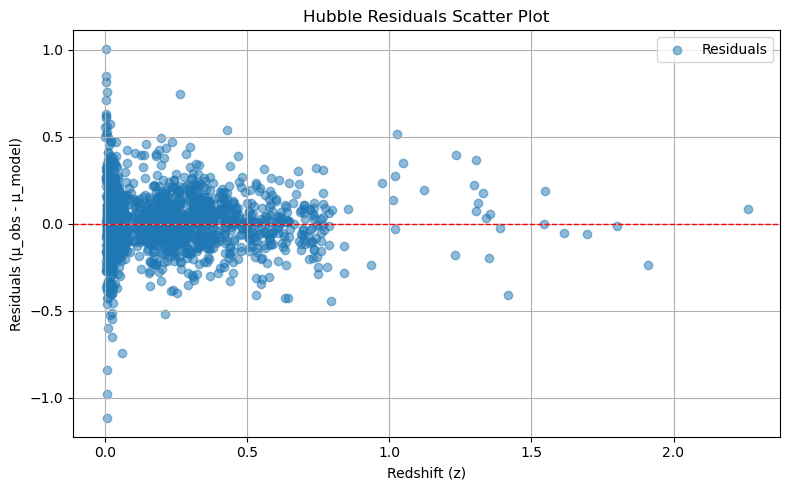

In [15]:
# Scatter plot of residuals
plt.figure(figsize=(8, 5))
plt.scatter(z, residuals, alpha=0.5, label='Residuals')

plt.axhline(0, color='red', linestyle='--', linewidth=1)

# Labeling
plt.xlabel('Redshift (z)')
plt.ylabel('Residuals (μ_obs - μ_model)')
plt.title('Hubble Residuals Scatter Plot')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 🔧 Fit with Fixed Matter Density

To reduce parameter degeneracy, let's fix $ \Omega_m = 0.3 $ and fit only for the Hubble constant $ H_0 $.


In [53]:
def mu_fixed_Om(z, H0):
    return mu_theory(z, H0, Omega_m=0.3)

# Try fitting with this fixed value
# Write a code for fitting and taking error out of the parameters
popt, pcov = curve_fit(mu_fixed_Om, z, mu, sigma=mu_err, p0=[H_guess], absolute_sigma=True)
H0_fit_n = popt[0]
H0_err_n = np.sqrt(pcov[0, 0])

print(f"Best-fitted H0 = {H0_fit_n:.2f} ± {H0_err_n:.2f} km/s/Mpc")


Best-fitted H0 = 73.53 ± 0.17 km/s/Mpc


In [54]:
def age_of_universe(H0, Omega_m):
    integrand = lambda z: 1.0 / ((1 + z) * E(z, Omega_m))
    integral, _ = quad(integrand, 0, np.inf)
    
    H0 = H0 * u.km / u.s / u.Mpc  # Convert to proper units
    t_H = (1 / H0).to(u.Gyr)      # Hubble time in Gyr

    t_0 = t_H * integral          # Age of universe = t_H * integral
    return t_0.value   # in Gyr

t0 = age_of_universe(H0_fit_n, 0.3)
print(f"Estimated age of Universe: {t0:.2f} Gyr")

Estimated age of Universe: 12.82 Gyr


## 🔍 Compare Low-z and High-z Subsamples

Finally, we examine whether the inferred value of $H_0$ changes with redshift by splitting the dataset into:
- **Low-z** supernovae ($ z < 0.1 $)
- **High-z** supernovae ($ z \geq 0.1 $)

We then fit each subset separately (keeping $ \Omega_m = 0.3 $) to explore any potential tension or trend with redshift.


In [56]:
# Split the data for the three columns and do the fitting again and see
z_split = 0.1
z_low = z[z < z_split]
mu_low = mu[z < z_split]
mu_err_low = mu_err[z < z_split]

z_high = z[z >= z_split]
mu_high = mu[z >= z_split]
mu_err_high = mu_err[z >= z_split]

def mu_fixed_Om_split(z, H0):
    return mu_theory(z, H0, Omega_m=0.3)

H0_low, _ = curve_fit(mu_fixed_Om_split, z_low, mu_low, sigma=mu_err_low, p0=[H_guess], absolute_sigma=True)
H0_high, _ = curve_fit(mu_fixed_Om_split, z_high, mu_high, sigma=mu_err_high, p0=[H_guess], absolute_sigma=True)

print(f"Low-z (z < {z_split}): H₀ = {H0_low[0]:.2f} km/s/Mpc")
print(f"High-z (z ≥ {z_split}): H₀ = {H0_high[0]:.2f} km/s/Mpc")


Low-z (z < 0.1): H₀ = 73.01 km/s/Mpc
High-z (z ≥ 0.1): H₀ = 73.85 km/s/Mpc


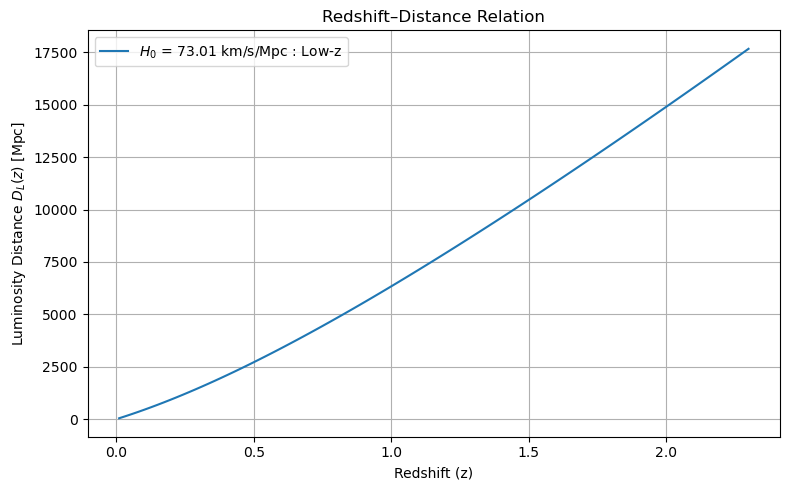

In [19]:
H0 = 73.01
omega0 = 0.3
z_vals = np.linspace(0.01, 2.3, 100)
dL_vals = [luminosity_distance(z, H0, omega0) for z in z_vals]

plt.figure(figsize=(8, 5))
plt.plot(z_vals, dL_vals, label=f'$H_0$ = {H0} km/s/Mpc : Low-z')
plt.xlabel("Redshift (z)")
plt.ylabel("Luminosity Distance $D_L(z)$ [Mpc]")
plt.title("Redshift–Distance Relation")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


ANALYSIS

1. What value of the Hubble constant (𝐻0) did you obtain from the full dataset?
   Ans : 73.53 ± 0.17 km/s/Mpc
   
2. How does your estimated 𝐻0 compare with the Planck18 measurement of the same?
   Ans :  Planck18 Measurement of H₀ : 67.4 ± 0.5 km/s/Mpc
          Estimated H₀ : 73.53 ± 0.17 km/s/Mpc
          The SH0ES estimate of H₀ = 73.53 ± 0.17 km/s/Mpc is significantly higher than the Planck 2018 value of 67.4 ± 0.5 km/s/Mpc, leading to a **\~5–6σ tension**. This discrepancy, known as the **Hubble tension**, may indicate unknown systematics or the need for **new physics beyond ΛCDM**.

3. What is the age of the Universe based on your value of $H_0$? (Assume Ω𝑚 = 0.3). How does it change for different values of Ω𝑚?
   Ans : When, Ω𝑚 = 0.3, the age of universe is 12.82 Gyr. When, Ω𝑚 is higher, universe expands slowly in early times, hence its younger. When its     value         is lower, it refers that universe expands faster.

4. Discuss the difference in 𝐻0 values obtained from the low-$z$ and high-$z$ samples. What could this imply?
   Ans : Low-z (z < 0.1): H₀ = 73.01 km/s/Mpc
        High-z (z ≥ 0.1): H₀ = 73.85 km/s/Mpc
        The slight increase in H₀ from low‑z to high‑z may hint at redshift-dependent effects or mild systematics in the dataset. It could also suggest         the need to test beyond ΛCDM models with evolving dark energy or additional physics.

5. Plot the residuals and comment on any trends or anomalies you observe.
    Ans : a. Centered around zero: Indicates the model fits well across redshifts.
          b. Low-z (z < 0.1): Dense data with small error bars; tight scatter.
          c. High-z (z > 1): Fewer data points with larger uncertainties.
          d. No significant trend: Residuals show no systematic drift with redshift.
          e. Slight low-z asymmetry: May hint at calibration or local effects.
          f. Overall fit consistent with ΛCDM: No clear anomalies or deviations.

6. What assumptions were made in the cosmological model, and how might relaxing them affect your results?
   Ans :  Assumptions Made in the Cosmological Model
             Initial guess for Hubble constant: 𝐻0 = 70km/s/Mpc
               Initial guess for matter density: Ω𝑚 = 0.3
          Effect of Relaxing These Assumptions
          Changing 𝐻0 guess: May affect the convergence speed of the fit, but not the final result if the optimizer works well.
          Varying Ω𝑚 : Alters the shape of the distance–redshift relation, which can impact the best-fit value of 𝐻0 and the inferred age of the                 universe.

7. Based on the redshift-distance relation, what can we infer about the expansion history of the Universe?
   Ans : The redshift–distance curve captures the Universe’s transition from early deceleration to late-time acceleration, strongly supporting the               existence of dark energy and aligning well with the ΛCDM cosmological model.

You can check your results and potential reasons for different values from accepted constant using this paper by authors of the [Pantheon+ dataset](https://arxiv.org/pdf/2310.11727)

You can find more about the dataset in the paper too